In [43]:
# Student-specific parameters:
STUDENT_NAME = "Celo"
STUDENT_ID = "TUPM-26-1941"
color1 = 'Reds'

print("Student:", STUDENT_NAME)
print("Student ID:", STUDENT_ID)
print("Map Color:", color1)

Student: Celo
Student ID: TUPM-26-1941
Map Color: Reds


In [44]:
import pandas as pd
import os

dataset_path = r"C:\Users\admin\Lab8_Data_Visualization_Celo\spotify_dataset\spotify_top_1000_tracks.csv"

df = pd.read_csv(dataset_path, encoding="utf-8")

In [45]:
# Group the dataset by year and count songs released.
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df = df.dropna(subset=['release_date','duration_min','popularity'])
df['year'] = df['release_date'].dt.year
year = df.groupby('year').size().sort_index()

# Subset or group data by year to show progression over time.
df = df.sort_values('year')
years = sorted(df['year'].unique())

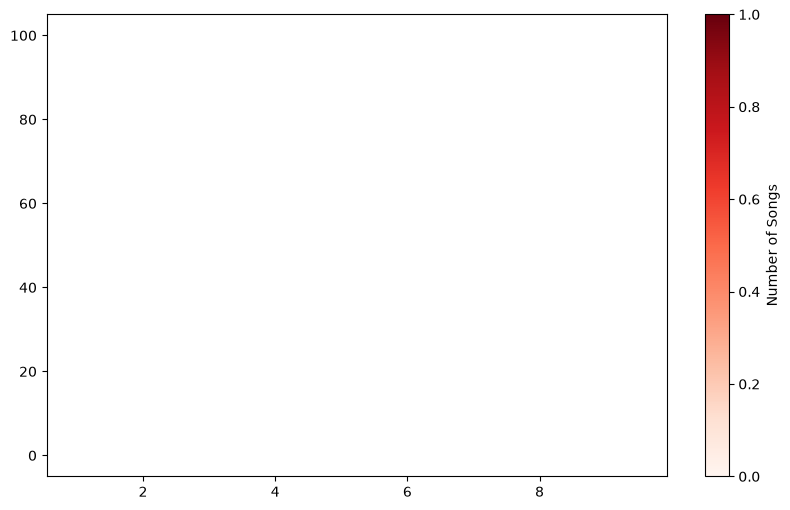

In [46]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import webbrowser

# Parameters for hexbin plot
fig, ax = plt.subplots(figsize=(10, 6))
x_min, x_max = df['duration_min'].min(), df['duration_min'].max()
y_min, y_max = 0, 100

# Use plt.hexbin to calculate the density of points in the duration vs popularity space.
hb = ax.hexbin([], [], gridsize=15, cmap=color1, extent=[x_min, x_max, y_min, y_max], mincnt=1)
cb = fig.colorbar(hb, ax=ax, label='Number of Songs')

In [47]:
# [OUTPUT] Animated hexbin density map showing where songs are concentrated in terms of duration and popularity.

# Animate frames per year to show the evolution of concentration.
def animate(i):
    ax.clear()
    current_year = years[i]
    subset = df[df['year'] <= current_year]
    
    ax.hexbin(
        subset['duration_min'], 
        subset['popularity'], 
        gridsize=15, 
        cmap=color1, 
        extent=[x_min, x_max, y_min, y_max], 
        mincnt=1
    )

    ax.set_xlim(x_min, x_max)
    ax.set_xlabel("Duration (minutes)", fontsize=12, fontname='Times New Roman')
    ax.set_ylim(y_min, y_max)
    ax.set_ylabel("Popularity Score (0-100)", fontsize=12, fontname='Times New Roman')
# [OUTPUT] Student name and ID displayed on each frame.
    ax.set_title(f"{STUDENT_NAME} - {STUDENT_ID}\nDuration vs. Popularity Density (Year: {current_year})", fontsize=14, fontname='Times New Roman')
    ax.grid(True, linestyle='--', alpha=1)

ani = FuncAnimation(fig, animate, frames=len(years), interval=50, repeat=False)

gif_path = os.path.abspath("yearly_popularity_trend.gif")
ani.save(gif_path, writer=PillowWriter(fps=1))
print(f" GIF saved successfully at: {gif_path}")

webbrowser.open(f"file://{gif_path}") 
plt.close(fig)

 GIF saved successfully at: c:\Users\admin\Lab8_Data_Visualization_Celo\yearly_popularity_trend.gif
